# Distance vs. Accuracy at Torrey Pines

**Question:** At Torrey Pines (North + South, home of the PGA TOUR's Farmers Insurance Open), is it more rewarding to hit it farther and miss more fairways, or hit it shorter and find more fairways? How does that trade-off compare with a typical PGA TOUR event?

**Data:** 25,558 player-event observations (760 at Torrey) from pgatour.com's per-event stats, 2017–2026 seasons. Built by `scripts/download_pga_stats.py` and `scripts/build_tidy_csv.py`.

**Method:** OLS of strokes gained on driving distance and fairway %, with Torrey interactions, event fixed effects and player fixed effects. Standard errors are clustered by player.

**Answer:** Distance is the better bet at Torrey. There, 10 extra yards is worth about as much as 9 points of fairways, against about 6 points at a typical event.

*The step-by-step working notebooks are `01_explore.ipynb` and `02_model.ipynb`. This notebook is the clean, end-to-end version.*

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Chart style shared by all three figures
TOUR, TORREY = "#2a78d6", "#eb6834"          # blue = typical tour event, orange = Torrey Pines
GRID, MUTED, INK2 = "#e1e0d9", "#898781", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.titlelocation": "left"})
SOURCE = "Data: pgatour.com per-event stats, 2017-2026 seasons."

df = pd.read_csv("../data/clean/pga_event_stats.csv")
df = df.dropna(subset=["distance", "fairway_pct", "sg_total"]).copy()
df["torrey"] = df["is_torrey"]
df["group"] = df["torrey"].map({1: "Torrey Pines", 0: "Other events"})
print(f"{len(df):,} player-events, {df['tournament_id'].nunique()} events, {df['player_id'].nunique():,} players; "
      f"{df['torrey'].sum()} at Torrey across {df.loc[df.torrey == 1, 'year'].nunique()} Farmers Insurance Opens")

25,558 player-events, 366 events, 940 players; 760 at Torrey across 10 Farmers Insurance Opens


## 2. What the data looks like

In [2]:
df.groupby("group")[["distance", "fairway_pct", "sg_total", "sg_ott"]].agg(["mean", "std"]).round(2).T

group             Other events  Torrey Pines
distance    mean        300.47        297.68
            std          14.21         11.45
fairway_pct mean         61.70         52.95
            std          10.75          8.90
sg_total    mean          0.73          0.65
            std           1.34          1.57
sg_ott      mean          0.12          0.09
            std           0.60          0.62

Torrey plays to about the same driving distance as other events but **players hit ~9 points fewer fairways** (53% vs. 62%).

**Figure 1:** each dot is one player at one event, colored by strokes gained that week (blue = gained, red = lost, capped at ±3). The cross marks each group's average.

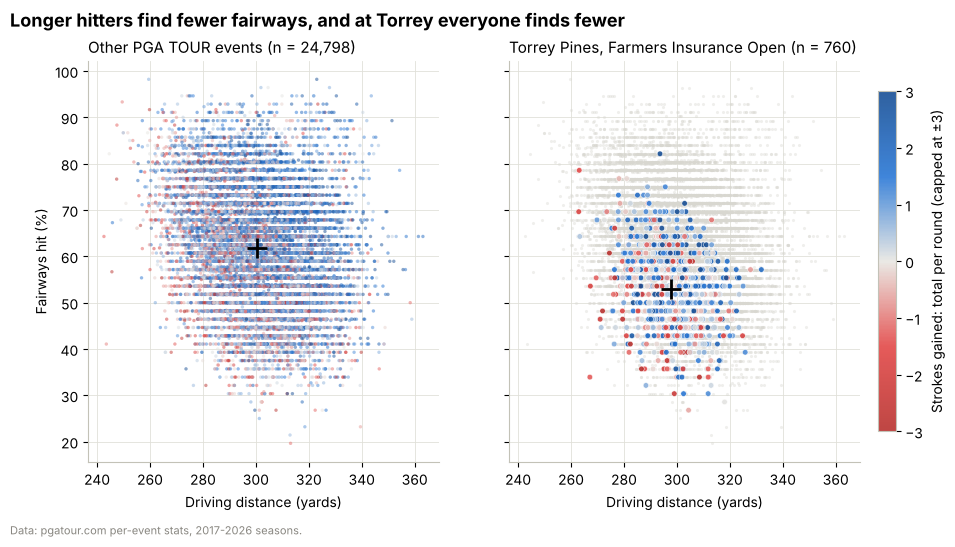

In [3]:
cmap = LinearSegmentedColormap.from_list("sg", ["#b8322f", "#e34948", "#e8e7e2", "#2a78d6", "#184f95"])
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)
other, torrey = df[df.torrey == 0], df[df.torrey == 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
axes[0].scatter(other.distance, other.fairway_pct, c=other.sg_total, cmap=cmap, norm=norm, s=6, alpha=0.5, linewidths=0)
axes[0].set_title(f"Other PGA TOUR events (n = {len(other):,})", fontsize=11)
axes[1].scatter(other.distance, other.fairway_pct, color="#d8d7d0", s=5, alpha=0.4, linewidths=0)
pts = axes[1].scatter(torrey.distance, torrey.fairway_pct, c=torrey.sg_total, cmap=cmap, norm=norm,
                      s=16, alpha=0.9, edgecolors="white", linewidths=0.4)
axes[1].set_title(f"Torrey Pines, Farmers Insurance Open (n = {len(torrey):,})", fontsize=11)
for ax, g in zip(axes, [other, torrey]):
    ax.plot(g.distance.mean(), g.fairway_pct.mean(), marker="+", color="black", markersize=14, mew=2)
    ax.set_xlabel("Driving distance (yards)")
    ax.grid(color=GRID, linewidth=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("Fairways hit (%)")
cb = fig.colorbar(pts, ax=axes, shrink=0.85, pad=0.02)
cb.set_label("Strokes gained: total per round (capped at ±3)")
fig.suptitle("Longer hitters find fewer fairways, and at Torrey everyone finds fewer",
             x=0.06, ha="left", fontsize=13, fontweight="bold")
fig.text(0.06, -0.03, SOURCE, fontsize=8, color=MUTED)
fig.savefig("../figures/fig1_distance_vs_fairways.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Regression models

We build up four models. The **interaction terms** (`distance:torrey`, `fairway_pct:torrey`) measure how much each slope changes at Torrey.

| Model | Adds | Why |
|---|---|---|
| A | Torrey and tour fit separately | Simplest version |
| B | One pooled model with interactions | Formal test of "is Torrey different?" |
| C | + event fixed effects | Compare each player with that week's field, removing course and weather |
| D | + player fixed effects | Compare each player with himself, removing the confounding from "better players are long *and* straight" |

Model D is the preferred specification. Standard errors are clustered by player because each player appears many times.

In [4]:
def fit(formula, data):
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": data["player_id"]})

INTERACT = "distance + fairway_pct + distance:torrey + fairway_pct:torrey"
models = {
    "A (tour only)":   fit("sg_total ~ distance + fairway_pct", df[df.torrey == 0]),
    "A (Torrey only)": fit("sg_total ~ distance + fairway_pct", df[df.torrey == 1]),
    "B pooled":        fit("sg_total ~ (distance + fairway_pct) * torrey", df),
    "C + event FE":    fit(f"sg_total ~ {INTERACT} + C(tournament_id)", df),
    "D + event & player FE": fit(f"sg_total ~ {INTERACT} + C(tournament_id) + C(player_id)", df),
}

KEY = ["distance", "fairway_pct", "distance:torrey", "fairway_pct:torrey"]
def cell(m, name):
    if name not in m.params: return ""
    stars = "***" if m.pvalues[name] < 0.01 else "**" if m.pvalues[name] < 0.05 else "*" if m.pvalues[name] < 0.1 else ""
    return f"{m.params[name]:.4f}{stars} ({m.bse[name]:.4f})"
table = pd.DataFrame({label: [cell(m, k) for k in KEY] + [f"{int(m.nobs):,}", f"{m.rsquared:.3f}"]
                      for label, m in models.items()}, index=KEY + ["N", "R²"])
table   # coefficient (clustered SE); * p<0.1, ** p<0.05, *** p<0.01

,A (tour only),A (Torrey only),B pooled,C + event FE,D + event & player FE
distance,0.0160*** (0.0009),0.0301*** (0.0046),0.0160*** (0.0009),0.0302*** (0.0017),0.0233*** (0.0014)
fairway_pct,0.0220*** (0.0009),0.0391*** (0.0063),0.0220*** (0.0009),0.0396*** (0.0014),0.0370*** (0.0012)
distance:torrey,,,0.0141*** (0.0046),0.0105** (0.0052),0.0099** (0.0049)
fairway_pct:torrey,,,0.0171*** (0.0063),0.0026 (0.0062),-0.0002 (0.0061)
N,"24,798",760,"25,558","25,558","25,558"
R²,0.046,0.069,0.047,0.144,0.253


**Reading the table:** in every model, both distance and accuracy pay off. The `distance:torrey` interaction is positive and significant in Models B–D, so **each yard is worth more at Torrey**. Once we compare within the same week (C) and within the same player (D), the `fairway_pct:torrey` interaction is about zero: **a fairway point is worth the same at Torrey as anywhere else**.

Adding player fixed effects (C → D) shrinks the tour distance slope from 0.030 to 0.023 per yard. That's the confounding: part of the raw distance effect was "better players are longer".

## 4. Turning coefficients into a trade-off

How many points of fairways is **10 extra yards** worth? Setting the two effects equal gives $X = 10\,\beta_{distance} / \beta_{fairway}$. For Torrey, each $\beta$ is the base slope plus its interaction. The 95% confidence interval uses the **delta method**, a first-order Taylor approximation of how uncertainty in the two coefficients carries through the ratio.

In [5]:
def weights(model, var, place):
    w = pd.Series(0.0, index=model.params.index)
    w[var] = 1
    if place == "Torrey":
        w[f"{var}:torrey"] = 1
    return w

def slope(model, var, place):
    """Estimate and SE of a slope (base + interaction at Torrey)."""
    w = weights(model, var, place)
    return w @ model.params, np.sqrt(w @ model.cov_params() @ w)

def tradeoff(model, place, yards=10):
    """Points of fairways that `yards` of distance is worth, with a delta-method 95% CI."""
    wd, wf, V = weights(model, "distance", place), weights(model, "fairway_pct", place), model.cov_params()
    bd, bf = wd @ model.params, wf @ model.params
    cov2 = np.array([[wd @ V @ wd, wd @ V @ wf], [wf @ V @ wd, wf @ V @ wf]])
    r = yards * bd / bf
    grad = np.array([yards / bf, -yards * bd / bf ** 2])
    se = np.sqrt(grad @ cov2 @ grad)
    return r, r - 1.96 * se, r + 1.96 * se

trade = pd.DataFrame([(label, place, *tradeoff(models[label], place))
                      for label in ["B pooled", "C + event FE", "D + event & player FE"]
                      for place in ["Tour", "Torrey"]],
                     columns=["model", "where", "10 yards = X pts fairways", "95% CI low", "95% CI high"]).round(1)
trade

,model,where,10 yards = X pts fairways,95% CI low,95% CI high
0,B pooled,Tour,7.3,6.4,8.2
1,B pooled,Torrey,7.7,5.0,10.4
2,C + event FE,Tour,7.6,6.7,8.5
3,C + event FE,Torrey,9.6,6.5,12.8
4,D + event & player FE,Tour,6.3,5.5,7.1
5,D + event & player FE,Torrey,9.0,5.7,12.3


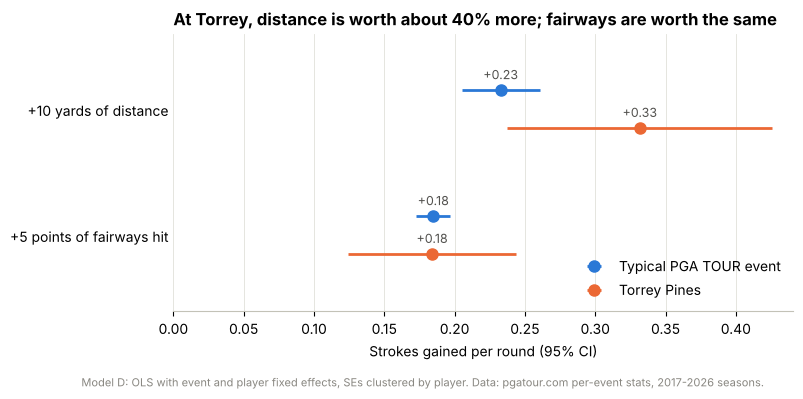

In [6]:
D = models["D + event & player FE"]
fig, ax = plt.subplots(figsize=(8, 3.6))
items = [("+10 yards of distance", "distance", 10), ("+5 points of fairways hit", "fairway_pct", 5)]
for i, (label, var, size) in enumerate(items):
    for j, (place, color, name) in enumerate([("Tour", TOUR, "Typical PGA TOUR event"), ("Torrey", TORREY, "Torrey Pines")]):
        est, se = slope(D, var, place)
        y = i + (-0.15 if j == 0 else 0.15)
        ax.errorbar(size * est, y, xerr=1.96 * size * se, fmt="o", color=color, markersize=8,
                    elinewidth=2, capsize=0, label=name if i == 0 else None)
        ax.annotate(f"{size*est:+.2f}", (size * est, y), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=9, color=INK2)
ax.set_yticks([0, 1]); ax.set_yticklabels([it[0] for it in items]); ax.tick_params(axis="y", length=0)
ax.set_ylim(1.6, -0.6); ax.set_xlim(left=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Strokes gained per round (95% CI)")
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("At Torrey, distance is worth about 40% more; fairways are worth the same", fontsize=12, fontweight="bold")
fig.text(0.01, -0.1, "Model D: OLS with event and player fixed effects, SEs clustered by player. " + SOURCE,
         fontsize=8, color=MUTED)
fig.savefig("../figures/fig2_value_of_distance_vs_fairways.png", dpi=200, bbox_inches="tight")
plt.show()

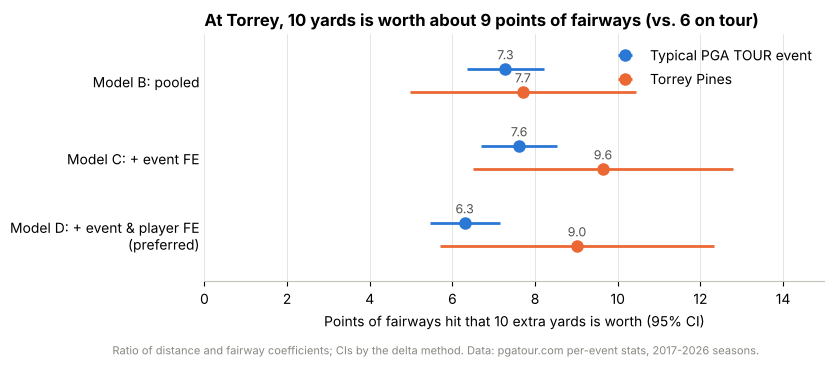

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
rows = [("Model B: pooled", models["B pooled"]), ("Model C: + event FE", models["C + event FE"]),
        ("Model D: + event & player FE\n(preferred)", D)]
for i, (label, m) in enumerate(rows):
    for j, (place, color, name) in enumerate([("Tour", TOUR, "Typical PGA TOUR event"), ("Torrey", TORREY, "Torrey Pines")]):
        r, lo, hi = tradeoff(m, place)
        y = i + (-0.15 if j == 0 else 0.15)
        ax.errorbar(r, y, xerr=[[r - lo], [hi - r]], fmt="o", color=color, markersize=8, elinewidth=2,
                    capsize=0, label=name if i == 0 else None)
        ax.annotate(f"{r:.1f}", (r, y), xytext=(0, 7), textcoords="offset points", ha="center",
                    fontsize=9, color=INK2)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows]); ax.tick_params(axis="y", length=0)
ax.set_ylim(len(rows) - 0.4, -0.6); ax.set_xlim(0, 15)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Points of fairways hit that 10 extra yards is worth (95% CI)")
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right")
ax.set_title("At Torrey, 10 yards is worth about 9 points of fairways (vs. 6 on tour)", fontsize=12, fontweight="bold")
fig.text(0.01, -0.12, "Ratio of distance and fairway coefficients; CIs by the delta method. " + SOURCE,
         fontsize=8, color=MUTED)
fig.savefig("../figures/fig3_tradeoff_yards_per_fairway.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Robustness: other strokes-gained outcomes
SG: Off-the-Tee isolates the drive itself. SG: Tee-to-Green removes putting, which has nothing to do with driving.

In [8]:
robust = {}
for outcome in ["sg_total", "sg_t2g", "sg_ott"]:
    d = df.dropna(subset=[outcome])
    m = fit(f"{outcome} ~ {INTERACT} + C(tournament_id) + C(player_id)", d)
    robust[outcome] = [cell(m, k) for k in KEY]
pd.DataFrame(robust, index=KEY)

,sg_total,sg_t2g,sg_ott
distance,0.0233*** (0.0014),0.0231*** (0.0011),0.0211*** (0.0006)
fairway_pct,0.0370*** (0.0012),0.0420*** (0.0011),0.0398*** (0.0005)
distance:torrey,0.0099** (0.0049),0.0111** (0.0046),0.0107*** (0.0017)
fairway_pct:torrey,-0.0002 (0.0061),-0.0045 (0.0050),-0.0077*** (0.0020)


The extra value of distance at Torrey shows up for all three outcomes. With SG: Off-the-Tee it's highly significant, and fairways are actually worth *less* at Torrey than on tour.

## 6. Findings
1. **Torrey is a fairway-killer, not a distance-killer.** Players hit about 53% of fairways at Torrey vs. 62% elsewhere, with nearly identical driving distance.
2. **At Torrey, distance is the better bet.** In the preferred model, 10 extra yards is worth about **9 points of fairways at Torrey vs. about 6 on a typical tour stop**. Each yard is worth roughly 40% more there (p ≈ 0.04), while a fairway point is worth the same.
3. **Controlling for skill matters.** Comparing each player with himself shrinks the distance effect by about a quarter, because better players tend to be both longer and straighter. The Torrey distance premium survives that control.

## 7. Limitations
- **Small Torrey sample:** 10 tournaments and 760 player-events, so the intervals are wide. The Torrey trade-off interval (about 6–12) overlaps the tour's (about 5.5–7).
- **Mostly cut-makers:** the tables mostly include players who made the cut, so the worst weeks are missing, which likely shrinks all slopes.
- **Course mix:** Torrey strokes gained covers only the South Course rounds (3 of 4), and we can't separate North from South with event-level data.
- **Association, not causation:** a player's distance and accuracy in a given week also reflect how well he's swinging, so this doesn't prove a strategy change would pay off.
- **Data terms:** pgatour.com's Terms of Use (§7(C)) prohibit automated downloading. The data was collected for personal, non-commercial study and is not redistributed in this repository.